In [ ]:
import json
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---------------- paths ----------------
RAW_FE = Path("vehicles.csv")                 # fueleconomy.gov
RAW_EV = Path("open-ev-data-v1.24.0.csv")     # OpenEV Data
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- scope ----------------
YEAR_MIN, YEAR_MAX = 2015, 2026

# ---------------- physical constants ----------------
MI_TO_KM = 1.609344
MPG_TO_L100KM = 100 * 3.785411784 / MI_TO_KM      # L/100km = 235.215 / mpg
KWH_PER_L = {                                     # lower heating value, energy per litre
    "Gasoline": 33.705 / 3.785411784,             # EPA MPGe definition: 33.705 kWh per US gallon
    "Diesel":   33.705 * 1.13 / 3.785411784,      # 1 gal diesel ≈ 1.13 gasoline-gallon-equivalent (AFDC)
}

# ---------------- running-cost assumptions (Malaysia, MYR) ----------------
# ILLUSTRATIVE values — please update before running
PRICE_MYR = {
    "RON95": 1.99,          # RM/L, BUDI95 price
    "RON97": 4.90,          # RM/L
    "Diesel": 5.27,         # RM/L, Peninsular
    "elec_home": 0.45,      # RM/kWh, residential effective tariff
    "elec_dc": 1.30,        # RM/kWh, public DC fast charging
}
HOME_CHARGING_SHARE = 0.70  # share of EV/PHEV energy charged at home (rest = public DC)
ANNUAL_KM = 20_000          # typical Malaysian annual mileage

# ---------------- entity-resolution settings ----------------
MATCH_MAX_YEAR_GAP = 1      # allow FE model year ±1 vs OpenEV year (EV specs usually carry over)

log = []                    # cleaning lineage: (step, rows)
def log_step(step, df):
    log.append((step, len(df)))
    print(f"{step:<55s} rows = {len(df):,}")

### LOAD DATA

In [6]:
fe_raw = pd.read_csv(RAW_FE, low_memory=False)
ev_raw = pd.read_csv(RAW_EV)
print("fueleconomy.gov :", fe_raw.shape)
print("OpenEV          :", ev_raw.shape)
fe_raw.head(3)

fueleconomy.gov : (50407, 84)
OpenEV          : (1189, 25)


,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,cityUF,co2,co2A,co2TailpipeAGpm,co2TailpipeGpm,comb08,comb08U,combA08,combA08U,combE,combinedCD,combinedUF,cylinders,displ,drive,engId,eng_dscr,feScore,fuelCost08,fuelCostA08,...,rangeCityA,rangeHwy,rangeHwyA,trany,UCity,UCityA,UHighway,UHighwayA,VClass,year,youSaveSpend,baseModel,guzzler,trans_dscr,tCharger,sCharger,atvType,fuelType2,rangeA,evMotor,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
0,14.17,0.00,0.00,0.00,19,0.00,0,0.00,0.00,0.00,0.00,-1,-1,0.00,423.19,21,0.00,0,0.00,0.00,0.00,0.00,4.00,2.00,Rear-Wheel Drive,9011,(FFS),-1,3200,0,...,0.00,0.00,0.00,Manual 5-spd,23.33,0.00,35.00,0.00,Two Seaters,1985,-4000,Spider,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
1,27.05,0.00,0.00,0.00,9,0.00,0,0.00,0.00,0.00,0.00,-1,-1,0.00,807.91,11,0.00,0,0.00,0.00,0.00,0.00,12.00,4.90,Rear-Wheel Drive,22020,(GUZZLER),-1,6100,0,...,0.00,0.00,0.00,Manual 5-spd,11.00,0.00,19.00,0.00,Two Seaters,1985,-18500,Testarossa,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
2,11.02,0.00,0.00,0.00,23,0.00,0,0.00,0.00,0.00,0.00,-1,-1,0.00,329.15,27,0.00,0,0.00,0.00,0.00,0.00,4.00,2.20,Front-Wheel Drive,2100,(FFS),-1,2500,0,...,0.00,0.00,0.00,Manual 5-spd,29.00,0.00,47.00,0.00,Subcompact Cars,1985,-500,Charger,NaN,SIL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [7]:
ev_raw.head(3)

,unique_code,make_slug,make_name,model_slug,model_name,year,trim_slug,trim_name,variant_slug,variant_name,vehicle_type,drivetrain,system_power_kw,system_torque_nm,battery_capacity_gross_kwh,battery_capacity_net_kwh,battery_chemistry,dc_max_power_kw,ac_max_power_kw,range_wltp_km,range_epa_km,acceleration_0_100_s,top_speed_kmh,charge_connectors,sources
0,audi:a6_e_tron:2024:a6_e_tron,audi,Audi,a6_e_tron,A6 e-tron,2024,base,Base,sportback,Sportback,PassengerCar,Rwd,350,550.00,100.00,94.90,li-ion,270.00,11.00,700.00,NaN,4.50,209.00,Ccs2,https://www.audi.com
1,audi:a6_e_tron:2024:a6_e_tron_avant,audi,Audi,a6_e_tron,A6 e-tron,2024,base,Base,avant,Avant,PassengerCar,Rwd,350,550.00,100.00,94.90,li-ion,270.00,11.00,700.00,NaN,4.50,209.00,Ccs2,https://www.audi.com
2,audi:a6_e_tron:2025:a6_e_tron,audi,Audi,a6_e_tron,A6 e-tron,2025,base,Base,sportback,Sportback,PassengerCar,Rwd,350,550.00,100.00,94.90,li-ion,270.00,11.00,700.00,NaN,4.50,209.00,Ccs2,https://www.audi.com


### CHECK MISSING

In [8]:
def audit(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} cols | exact duplicate rows: {df.duplicated().sum()}")
    return out

audit(fe_raw, "fueleconomy.gov").sort_values("pct_missing", ascending=False).head(20)

fueleconomy.gov: 50,407 rows x 84 cols | exact duplicate rows: 0


,dtype,n_missing,pct_missing,n_unique,example
c240bDscr,object,50272,99.70,7,dual charger
c240Dscr,object,50266,99.70,5,single charger
sCharger,object,49240,97.70,1,S
rangeA,object,48397,96.00,253,360
fuelType2,object,48394,96.00,4,Natural Gas
guzzler,object,47548,94.30,3,T
evMotor,object,46771,92.80,619,62 KW AC Induction
atvType,object,43547,86.40,10,Diesel
tCharger,object,38620,76.60,1,T
trans_dscr,object,35363,70.20,52,SIL


In [9]:
# Sentinel scan: how often do "impossible" -1 / 0 values appear in measured fields?
sentinel_cols = ["co2", "co2TailpipeGpm", "feScore", "ghgScore", "comb08", "combE", "range", "charge240", "cityA08"]
pd.DataFrame({
    "n_minus1": (fe_raw[sentinel_cols] == -1).sum(),
    "n_zero": (fe_raw[sentinel_cols] == 0).sum(),
    "n_rows": len(fe_raw),
})

,n_minus1,n_zero,n_rows
co2,31939,1652,50407
co2TailpipeGpm,0,1652,50407
feScore,32012,0,50407
ghgScore,32012,0,50407
comb08,0,0,50407
combE,0,48308,50407
range,0,48308,50407
charge240,0,48372,50407
cityA08,0,48392,50407


In [10]:
audit(ev_raw, "OpenEV")

OpenEV: 1,189 rows x 25 cols | exact duplicate rows: 0


,dtype,n_missing,pct_missing,n_unique,example
unique_code,object,0,0.00,1189,audi:a6_e_tron:2024:a6_e_tron
make_slug,object,0,0.00,65,audi
make_name,object,0,0.00,65,Audi
model_slug,object,0,0.00,260,a6_e_tron
model_name,object,0,0.00,260,A6 e-tron
year,int64,0,0.00,3,2024
trim_slug,object,0,0.00,93,base
trim_name,object,0,0.00,96,Base
variant_slug,object,605,50.90,137,sportback
variant_name,object,605,50.90,143,Sportback


### CLEANING fueleconomy.gov

In [11]:
fe = fe_raw.copy()
log_step("raw fueleconomy.gov", fe)

fe = fe[fe["year"].between(YEAR_MIN, YEAR_MAX)]
log_step(f"model years {YEAR_MIN}-{YEAR_MAX}", fe)

out_of_scope = fe["atvType"].isin(["FCV", "eFCV", "CNG", "Bifuel (CNG)", "Bifuel (LPG)"])
print("dropped out-of-scope fuels:\n", fe.loc[out_of_scope, "atvType"].value_counts().to_string())
fe = fe[~out_of_scope].copy()
log_step("drop hydrogen / natural-gas / LPG", fe)

raw fueleconomy.gov                                     rows = 50,407
model years 2015-2026                                   rows = 15,455
dropped out-of-scope fuels:
 atvType
FCV             41
Bifuel (CNG)     2
eFCV             2
CNG              1
drop hydrogen / natural-gas / LPG                       rows = 15,409


In [12]:
minus1_cols = ["co2", "co2A", "feScore", "ghgScore", "ghgScoreA"]
zero_na_cols = ["cityA08", "highwayA08", "combA08", "cityE", "highwayE", "combE", "cityUF", "highwayUF",
                "combinedUF", "range", "rangeCity", "rangeHwy", "rangeCityA", "rangeHwyA", "charge240",
                "fuelCostA08", "co2TailpipeAGpm", "co2TailpipeGpm", "barrelsA08", "phevCity", "phevHwy", "phevComb"]
fe[minus1_cols] = fe[minus1_cols].replace(-1, np.nan)
fe[zero_na_cols] = fe[zero_na_cols].replace(0, np.nan)

# rangeA is stored as text (e.g. "35" or "20/25"); take the first number (combined electric range of PHEVs)
fe["rangeA"] = pd.to_numeric(fe["rangeA"].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
fe["rangeA"] = fe["rangeA"].replace(0, np.nan)
print("non-null after sentinel fix:\n", fe[["co2", "feScore", "combE", "range", "rangeA"]].notna().sum().to_string())

non-null after sentinel fix:
 co2        15409
feScore    15409
combE       1797
range       1797
rangeA       848


In [13]:
fe["turbo"] = fe["tCharger"].notna()
fe["supercharger"] = fe["sCharger"].eq("S")
fe["gas_guzzler"] = fe["guzzler"].notna()
fe["start_stop"] = fe["startStop"].map({"Y": True, "N": False})
fe["phev_blended"] = fe["phevBlended"].astype(str).str.lower().eq("true")
fe[["turbo", "supercharger", "gas_guzzler", "start_stop"]].mean().rename("share_true").to_frame()

,share_true
turbo,0.50
supercharger,0.04
gas_guzzler,0.05
start_stop,0.51


In [14]:
MAKE_FIX = {"Vinfast": "VinFast"}
fe["make"] = fe["make"].str.strip().replace(MAKE_FIX)
fe["model"] = fe["model"].str.strip().str.replace(r"\s+", " ", regex=True)

DRIVE_MAP = {
    "Front-Wheel Drive": "FWD", "Rear-Wheel Drive": "RWD",
    "All-Wheel Drive": "AWD", "4-Wheel or All-Wheel Drive": "AWD",
    "4-Wheel Drive": "4WD", "Part-time 4-Wheel Drive": "4WD", "2-Wheel Drive": "2WD",
}
fe["drivetrain"] = fe["drive"].map(DRIVE_MAP)

def size_class(v):
    v = v.lower()
    if "pickup" in v:            return "Small Pickup" if "small" in v else "Standard Pickup"
    if "sport utility" in v:     return "Small SUV" if "small" in v else "Standard SUV"
    if "minivan" in v:           return "Minivan"
    if "van" in v:               return "Van"
    if "special purpose" in v:   return "Special Purpose"
    if "station wagon" in v:     return "Station Wagon"
    if "two seater" in v:        return "Two Seater"
    for s in ["minicompact", "subcompact", "compact", "midsize", "large"]:
        if v.startswith(s):      return s.capitalize() + " Car"
    return "Other"

def coarse_class(s):
    if "Pickup" in s: return "Pickup"
    if "SUV" in s:    return "SUV"
    if "van" in s.lower(): return "Van"
    if s == "Special Purpose": return "Special Purpose"
    return "Car"

fe["size_class"] = fe["VClass"].map(size_class)
fe["vehicle_class"] = fe["size_class"].map(coarse_class)

def parse_trany(t):
    if pd.isna(t):
        return pd.Series([np.nan, np.nan])
    g = re.search(r"(\d+)", t)
    n = float(g.group(1)) if g else np.nan
    if t.startswith("Manual"):                           kind = "Manual"
    elif re.search(r"\((?:A1|AV-S1)\)", t):             kind, n = "Single-speed", 1.0   # exact: AV-S10 is a CVT
    elif "variable" in t or "(AV" in t:                  kind, n = "CVT", np.nan
    elif "(AM" in t:                                     kind = "Automated manual (DCT)"
    else:                                                kind = "Automatic"
    return pd.Series([kind, n])

fe[["transmission_type", "n_gears"]] = fe["trany"].apply(parse_trany)

print("raw VClass labels:", fe["VClass"].nunique(), "-> size_class:", fe["size_class"].nunique(),
      "-> vehicle_class:", fe["vehicle_class"].nunique())
pd.crosstab(fe["size_class"], fe["vehicle_class"])

raw VClass labels: 22 -> size_class: 14 -> vehicle_class: 5


vehicle_class,Car,Pickup,SUV,Special Purpose,Van
size_class,,,,,
Compact Car,1642,0,0,0,0
Large Car,1220,0,0,0,0
Midsize Car,2051,0,0,0,0
Minicompact Car,570,0,0,0,0
Minivan,0,0,0,0,119
Small Pickup,0,283,0,0,0
Small SUV,0,0,3053,0,0
Special Purpose,0,0,0,261,0
Standard Pickup,0,1187,0,0,0


In [15]:
fe.groupby(["transmission_type"])["trany"].agg(lambda s: ", ".join(sorted(s.unique())[:6]))

transmission_type
Automated manual (DCT)    Automatic (AM-S10), Automatic (AM-S6), Automat...
Automatic                 Automatic (A2), Automatic (S10), Automatic (S4...
CVT                       Automatic (AV-S10), Automatic (AV-S6), Automat...
Manual                             Manual 5-spd, Manual 6-spd, Manual 7-spd
Single-speed                              Automatic (A1), Automatic (AV-S1)
Name: trany, dtype: object

In [16]:
fe["battery_voltage"] = pd.to_numeric(fe["evMotor"].str.extract(r"(\d+)\s*V\b", flags=re.I)[0], errors="coerce")

def classify_powertrain(r):
    atv = r["atvType"]
    if atv == "EV":             return "BEV"
    if atv == "Plug-in Hybrid": return "PHEV"
    if atv == "Hybrid":
        text = f"{r['eng_dscr']} {r['model']}"
        if re.search(r"mild|eassist|etorque", text, re.I) or (r["battery_voltage"] < 100):
            return "MHEV"
        return "HEV"
    return "ICE"

fe["powertrain"] = fe.apply(classify_powertrain, axis=1)

FUEL_MAP = {"Regular Gasoline": "Regular", "Midgrade Gasoline": "Regular", "Premium Gasoline": "Premium",
            "Diesel": "Diesel", "Electricity": "Electricity"}
fe["fuel_grade"] = fe["fuelType1"].map(FUEL_MAP)
fe["fuel_family"] = np.where(fe["fuel_grade"].eq("Diesel"), "Diesel",
                     np.where(fe["fuel_grade"].eq("Electricity"), "Electricity", "Gasoline"))
fe["flex_fuel"] = fe["atvType"].eq("FFV")

pd.crosstab(fe["atvType"].fillna("(none: conventional)"), fe["powertrain"], margins=True)

powertrain,BEV,HEV,ICE,MHEV,PHEV,All
atvType,,,,,,
(none: conventional),0,0,11440,0,0,11440
Diesel,0,0,308,0,0,308
EV,1373,0,0,0,0,1373
FFV,0,0,424,0,0,424
Hybrid,0,655,0,785,0,1440
Plug-in Hybrid,0,0,0,0,424,424
All,1373,655,12172,785,424,15409


In [17]:
fe[fe["powertrain"].isin(["MHEV", "HEV"])].groupby("powertrain")[["city08", "highway08", "battery_voltage"]].median()

,city08,highway08,battery_voltage
powertrain,,,
HEV,39.00,36.00,259.00
MHEV,20.00,26.00,48.00


In [18]:
is_bev = fe["powertrain"].eq("BEV")
is_phev = fe["powertrain"].eq("PHEV")
burns_fuel = ~is_bev

for part, col in [("city", "city08"), ("hwy", "highway08"), ("comb", "comb08")]:
    fe[f"fuel_l_100km_{part}"] = np.where(burns_fuel & (fe[col] > 0), MPG_TO_L100KM / fe[col], np.nan)
for part, col in [("city", "cityE"), ("hwy", "highwayE"), ("comb", "combE")]:
    fe[f"elec_kwh_100km_{part}"] = np.where(is_bev | is_phev, fe[col] / MI_TO_KM, np.nan)

fe["mpg_or_mpge_comb"] = fe["comb08"]                       # keep original headline figure for reference
fe["co2_g_km"] = np.where(is_bev, 0.0, fe["co2TailpipeGpm"] / MI_TO_KM)
fe["range_km"] = np.where(is_bev, fe["range"] * MI_TO_KM, np.nan)
fe["phev_elec_range_km"] = np.where(is_phev, fe["rangeA"] * MI_TO_KM, np.nan)
fe["phev_utility_factor"] = np.where(is_phev, fe["combinedUF"], np.nan)
fe["charge_time_240v_h"] = np.where(is_bev | is_phev, fe["charge240"], np.nan)

# unified energy intensity (kWh per 100 km)
fuel_kwh_per_l = fe["fuel_family"].map(KWH_PER_L).fillna(KWH_PER_L["Gasoline"])  # PHEV burns gasoline
fuel_energy = fe["fuel_l_100km_comb"] * fuel_kwh_per_l
uf = fe["phev_utility_factor"]
fe["energy_kwh_100km"] = np.select(
    [is_bev, is_phev],
    [fe["elec_kwh_100km_comb"], uf * fe["elec_kwh_100km_comb"] + (1 - uf) * fuel_energy],
    default=fuel_energy)

fe.groupby("powertrain")[["fuel_l_100km_comb", "elec_kwh_100km_comb", "energy_kwh_100km", "co2_g_km"]].median()

,fuel_l_100km_comb,elec_kwh_100km_comb,energy_kwh_100km,co2_g_km
powertrain,,,,
BEV,NaN,22.60,22.60,0.00
HEV,6.19,NaN,55.11,145.40
ICE,10.69,NaN,95.20,252.90
MHEV,10.23,NaN,91.06,244.20
PHEV,9.05,31.69,55.40,103.77


In [19]:
def parse_motor_kw(s):
    if pd.isna(s):
        return np.nan
    s = re.sub(r"\(?\d+\.?\d*\s*kw-?hr?\b[^)]*\)?", " ", s.lower())          # drop battery-pack capacity "(90 kW-hr ...)"
    tot = re.search(r"\((\d+\.?\d*)\s*kw\)", s)
    if tot:                                                                 # explicit total: "2 @ 150 kw (300 kw)"
        return float(tot.group(1))
    s = re.sub(r"(\d)\s*@\s*(\d+\.?\d*)", lambda m: " and ".join([m.group(2)] * int(m.group(1))), s)
    lists = re.findall(r"((?:\d+\.?\d*\s*(?:,|and|&|\+)\s*)*\d+\.?\d*)\s*-?\s*kw", s)
    if not lists:                                                           # "193 (front) 193 (rear)"
        lists = re.findall(r"(\d+\.?\d*)\s*\((?:front|rear)\)", s)
    total = sum(float(x) for grp in lists for x in re.findall(r"\d+\.?\d*", grp))
    return total or np.nan

fe["motor_kw_fe"] = np.where(is_bev | is_phev, fe["evMotor"].map(parse_motor_kw), np.nan)
print("BEV rows with parsed motor kW:", fe.loc[is_bev, "motor_kw_fe"].notna().mean().round(3))
tests = ["98 and 195 kW AC 3-Phase", "2 @ 150 kw (300 kw)", "164 (front) 350 (rear) (90 kW-hr battery pack)",
         "270 kW AC Induction (75 kW-hr battery pack)", "F: 160kW R: 270kW", "288V Ni-MH"]
pd.DataFrame({"evMotor": tests, "parsed_kw": [parse_motor_kw(t) for t in tests]})

BEV rows with parsed motor kW: 0.961


,evMotor,parsed_kw
0,98 and 195 kW AC 3-Phase,293.00
1,2 @ 150 kw (300 kw),300.00
2,164 (front) 350 (rear) (90 kW-hr battery pack),514.00
3,270 kW AC Induction (75 kW-hr battery pack),270.00
4,F: 160kW R: 270kW,430.00
5,288V Ni-MH,NaN


In [20]:
spec_cols = ["year", "make", "model", "powertrain", "fuel_grade", "VClass", "drive", "trany", "displ", "cylinders",
             "turbo", "supercharger", "city08", "highway08", "comb08", "combE", "range", "co2TailpipeGpm"]
n_dup = fe.duplicated(spec_cols).sum()
print(f"specification duplicates: {n_dup}")
fe = fe.drop_duplicates(spec_cols, keep="first")
log_step("drop specification duplicates", fe)

specification duplicates: 132
drop specification duplicates                           rows = 15,277


In [21]:
checks = {
    "fuel L/100km out of [2, 40]": burns_fuel.reindex(fe.index) & ~fe["fuel_l_100km_comb"].between(2, 40),
    "elec kWh/100km out of [8, 70]": fe["elec_kwh_100km_comb"].notna() & ~fe["elec_kwh_100km_comb"].between(8, 70),
    "BEV without combE": fe["powertrain"].eq("BEV") & fe["elec_kwh_100km_comb"].isna(),
    "BEV range missing": fe["powertrain"].eq("BEV") & fe["range_km"].isna(),
    "city or highway missing": fe["city08"].le(0) | fe["highway08"].le(0),
}
viol = pd.DataFrame(checks)
print(viol.sum().to_string())
bad = viol.any(axis=1)
display(fe.loc[bad, ["year", "make", "model", "powertrain", "comb08", "combE", "range"]].head(10))
fe = fe[~bad].copy()
log_step("drop physically implausible records", fe)

fuel L/100km out of [2, 40]      0
elec kWh/100km out of [8, 70]    0
BEV without combE                0
BEV range missing                0
city or highway missing          0


,year,make,model,powertrain,comb08,combE,range


drop physically implausible records                     rows = 15,277


### CLEANING OpenEV

In [22]:
ev = ev_raw.copy()
log_step("raw OpenEV", ev)
for c in ev.select_dtypes("object"):
    ev[c] = ev[c].str.strip()

ev["make_name"] = ev["make_name"].replace({"Mini": "MINI", "MG Motor": "MG"})
ev["vehicle_class"] = ev["vehicle_type"].map({"PassengerCar": "Car", "Suv": "SUV", "Pickup": "Pickup",
                                               "Van": "Van", "Other": "Special Purpose"})
ev["drivetrain"] = ev["drivetrain"].str.upper()

ev_checks = pd.DataFrame({
    "gross < net battery": ev["battery_capacity_gross_kwh"] < ev["battery_capacity_net_kwh"],
    "net battery <= 0": ev["battery_capacity_net_kwh"] <= 0,
    "power <= 0": ev["system_power_kw"] <= 0,
    "0-100 outside 1.5-25 s": ~ev["acceleration_0_100_s"].between(1.5, 25) & ev["acceleration_0_100_s"].notna(),
    "range EPA > WLTP*1.3": ev["range_epa_km"] > ev["range_wltp_km"] * 1.3,
})
print(ev_checks.sum().to_string())

raw OpenEV                                              rows = 1,189
gross < net battery       0
net battery <= 0          0
power <= 0                0
0-100 outside 1.5-25 s    0
range EPA > WLTP*1.3      0


In [23]:
ratio = (ev["battery_capacity_gross_kwh"] / ev["battery_capacity_net_kwh"]).median()
ev["battery_gross_imputed"] = ev["battery_capacity_gross_kwh"].isna()
ev["battery_capacity_gross_kwh"] = ev["battery_capacity_gross_kwh"].fillna(ev["battery_capacity_net_kwh"] * ratio)
print(f"median gross/net ratio = {ratio:.3f}; imputed {ev['battery_gross_imputed'].sum()} values")

ev["has_dc_charging"] = ev["dc_max_power_kw"].notna()
ev["kwh_100km_wltp_btw"] = ev["battery_capacity_net_kwh"] / ev["range_wltp_km"] * 100
ev["kwh_100km_epa_btw"] = ev["battery_capacity_net_kwh"] / ev["range_epa_km"] * 100
ev["dc_c_rate"] = ev["dc_max_power_kw"] / ev["battery_capacity_net_kwh"]
ev["primary_connector"] = ev["charge_connectors"].str.split("|").str[0]
ev[["kwh_100km_wltp_btw", "kwh_100km_epa_btw", "dc_c_rate"]].describe().T

median gross/net ratio = 1.055; imputed 4 values


,count,mean,std,min,25%,50%,75%,max
kwh_100km_wltp_btw,739.00,15.95,3.93,7.20,13.82,15.00,16.78,33.81
kwh_100km_epa_btw,395.00,20.75,4.34,12.43,17.62,20.00,24.43,32.05
dc_c_rate,"1,144.00",2.11,0.70,0.76,1.67,2.00,2.42,6.83


In [24]:
both = ev.dropna(subset=["range_wltp_km", "range_epa_km"])
r = both["range_epa_km"] / both["range_wltp_km"]
rng = np.random.default_rng(42)
boot = np.array([np.median(rng.choice(r, len(r))) for _ in range(5000)])
EPA_PER_WLTP = float(np.median(r))
print(f"n = {len(r)} vehicles with both ranges")
print(f"EPA/WLTP ratio: median = {EPA_PER_WLTP:.3f}, 95% bootstrap CI = [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")
print(f"Pearson r(WLTP, EPA) = {stats.pearsonr(both['range_wltp_km'], both['range_epa_km'])[0]:.3f}")

# EPA-equivalent range for every OpenEV trim (observed EPA where available, otherwise converted WLTP)
ev["range_epa_equiv_km"] = ev["range_epa_km"].fillna(ev["range_wltp_km"] * EPA_PER_WLTP)
ev["range_epa_is_estimated"] = ev["range_epa_km"].isna() & ev["range_wltp_km"].notna()

n = 269 vehicles with both ranges
EPA/WLTP ratio: median = 0.773, 95% bootstrap CI = [0.767, 0.785]
Pearson r(WLTP, EPA) = 0.776


### Matching fueleconomy.gov EVs to OpenEV

In [25]:
NOISE = re.compile(r"\b(awd|rwd|fwd|2wd|4wd|4x4|all4|4matic|4motion|quattro|xdrive|e-?4orce|\d+\s*(?:inch|in)\b|"
                   r"inch|wheels?|tires?|tyres?|with|w/|and|edition)\b")
MAKE_KEY_ALIAS = {"mg motor": "mg", "bugatti rimac": "rimac"}
MODEL_ALIAS = {                                     # documented renames: (make, regex on FE name) -> OpenEV name
    ("volvo", r"\bxc40 recharge\b"): "ex40",          # renamed EX40 in 2024
    ("volvo", r"\bc40 recharge\b"): "ec40",           # renamed EC40 in 2024
    ("toyota", r"^bz\b"): "bz4x",                      # bZ4X renamed "bZ" for MY2026
    ("mercedes-benz", r"^cla ?\d{3}\b"): "cla ev",     # US "CLA250 ... with EQ Tech" = OpenEV "CLA EV"
}

def ascii_lower(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()

def make_key(s):
    k = ascii_lower(s).strip()
    return MAKE_KEY_ALIAS.get(k, k)

def norm_name(s, make=None):
    s = ascii_lower(s)
    if make:
        s = re.sub(rf"^\s*{re.escape(make)}\s+", " ", s)                  # "Polestar 2" -> "2"
        for (mk, pattern), new in MODEL_ALIAS.items():
            if mk == make:
                s = re.sub(pattern, new, s)
    s = re.sub(r"[()\[\],/:+]", " ", s).replace("-", " ").replace(".", " ")
    s = NOISE.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip()

ev["make_key"] = ev["make_name"].map(make_key)
ev["model_key"] = [norm_name(m, mk) for m, mk in zip(ev["model_name"], ev["make_key"])]
ev["model_tokens"] = ev["model_key"].str.split().map(frozenset)
ev["trim_key"] = (ev["trim_name"] + " " + ev["variant_name"].fillna("")).map(norm_name)

fe["make_key"] = fe["make"].map(make_key)
fe["model_key"] = [norm_name(m, mk) for m, mk in zip(fe["model"], fe["make_key"])]

pd.DataFrame({"raw": ["Model 3 Long Range AWD (19in wheels)", "EQE 350 4matic (SUV)", "XC40 Recharge twin"],
              "normalised": [norm_name("Model 3 Long Range AWD (19in wheels)", "tesla"),
                             norm_name("EQE 350 4matic (SUV)", "mercedes-benz"),
                             norm_name("XC40 Recharge twin", "volvo")]})

,raw,normalised
0,Model 3 Long Range AWD (19in wheels),model 3 long range
1,EQE 350 4matic (SUV),eqe 350 suv
2,XC40 Recharge twin,ex40 twin


In [26]:
DRIVE_TO_OE = {"FWD": "FWD", "RWD": "RWD", "AWD": "AWD", "4WD": "AWD"}
ev_by_make = {k: g for k, g in ev.groupby("make_key")}

def match_vehicle(row):
    cands = ev_by_make.get(row["make_key"])
    if cands is None:
        return None
    fe_tokens = set(row["model_key"].split())
    ok = cands[cands["model_tokens"].map(lambda t: t <= fe_tokens)]                 # stage 1: token containment
    if ok.empty:
        return None
    best_len = ok["model_tokens"].map(len).max()
    ok = ok[ok["model_tokens"].map(len) == best_len]
    if ok["model_key"].nunique() > 1:                                                # ambiguous model -> no match
        return None
    gap = (ok["year"] - row["year"]).abs()
    if gap.min() > MATCH_MAX_YEAR_GAP:
        return None
    ok = ok[gap == gap.min()]

    residual = " ".join(t for t in row["model_key"].split() if t not in ok["model_tokens"].iloc[0])
    fe_range = row["range_km"]
    rng_diff = (ok["range_epa_equiv_km"] - fe_range).abs() / fe_range
    score = (ok["drivetrain"].eq(DRIVE_TO_OE.get(row["drivetrain"])) * 20                 # stage 2: trim scoring
             + (40 * (1 - rng_diff / 0.20)).clip(lower=0).fillna(0)
             + ok["trim_key"].map(lambda t: fuzz.token_set_ratio(residual, t) * 0.30 if residual else 0))
    best = score.idxmax()
    return {"fe_index": row.name, "oe_index": best, "match_score": score[best],
            "match_year_gap": int(gap.min()), "match_range_diff": rng_diff[best]}

bev_fe = fe[fe["powertrain"].eq("BEV")]
matches = pd.DataFrame([m for m in bev_fe.apply(match_vehicle, axis=1) if m is not None]).set_index("fe_index")
matches["match_confidence"] = pd.cut(matches["match_range_diff"], [-np.inf, 0.10, 0.25, np.inf],
                                     labels=["high", "medium", "low"]).astype(str)
matches.loc[matches["match_range_diff"].isna(), "match_confidence"] = "unverified"

eligible = bev_fe["year"].between(ev["year"].min() - MATCH_MAX_YEAR_GAP, ev["year"].max() + MATCH_MAX_YEAR_GAP)
print(f"FE BEVs in OpenEV's year window : {eligible.sum()}")
print(f"matched                          : {len(matches)} ({len(matches) / eligible.sum():.1%})")
matches["match_confidence"].value_counts().to_frame("n")

FE BEVs in OpenEV's year window : 1146
matched                          : 981 (85.6%)


,n
match_confidence,
high,705
medium,205
low,71


In [27]:
cov = (bev_fe[eligible].assign(matched=lambda d: d.index.isin(matches.index))
       .groupby("make")["matched"].agg(n="size", match_rate="mean").sort_values("n", ascending=False))
cov.T

make,Rivian,BMW,Porsche,Tesla,Mercedes-Benz,Audi,Lucid,Ford,Hyundai,Kia,Nissan,Chevrolet,Volvo,Polestar,Volkswagen,Toyota,Cadillac,Genesis,GMC,Lexus,Dodge,Subaru,Rolls-Royce,Maserati,Honda,VinFast,MINI,Jeep,Acura,Fiat,Jaguar,Bugatti Rimac,Fisker,Mazda,Lordstown
n,161.00,119.00,84.00,74.00,65.00,64.00,57.00,49.00,45.00,41.00,37.00,37.00,34.00,33.00,26.00,23.00,23.00,22.00,20.00,20.00,19.00,13.00,12.00,10.00,9.00,9.00,7.00,7.00,6.00,6.00,4.00,4.00,3.00,2.00,1.00
match_rate,1.00,1.00,1.00,0.77,1.00,0.66,1.00,1.00,1.00,0.00,0.92,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.65,0.00,0.00,1.00,0.60,1.00,1.00,1.00,0.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00


In [28]:
def show_pairs(idx):
    m = matches.loc[idx]
    return pd.DataFrame({
        "FE (year | make | model)": fe.loc[idx, "year"].astype(str) + " | " + fe.loc[idx, "make"] + " | " + fe.loc[idx, "model"],
        "OpenEV (year | model | trim | variant)": (ev.loc[m["oe_index"], "year"].astype(str) + " | " + ev.loc[m["oe_index"], "model_name"]
                                                   + " | " + ev.loc[m["oe_index"], "trim_name"] + " | " + ev.loc[m["oe_index"], "variant_name"].fillna("-")).values,
        "FE range km": fe.loc[idx, "range_km"].round(0).values,
        "OE EPA-eq km": ev.loc[m["oe_index"], "range_epa_equiv_km"].round(0).values,
        "confidence": m["match_confidence"].values,
    }).reset_index(drop=True)

show_pairs(matches.sample(15, random_state=7).index)

,FE (year | make | model),OpenEV (year | model | trim | variant),FE range km,OE EPA-eq km,confidence
0,2025 | Rivian | R1S Dual Standard (22in),2025 | R1S | Adventure | Quad Motor Large Pack,435.00,508.00,medium
1,2025 | BMW | i7 eDrive50 Sedan (20 inch Wheels),2025 | i7 | xDrive60 | -,484.00,505.00,high
2,2024 | Lucid | Air G Touring XR AWD with 20 in...,2024 | Air | Pure | Grand Touring,781.00,830.00,high
3,2023 | Rivian | R1T (20 inch wheels),2023 | R1T | Adventure | -,465.00,505.00,high
4,2025 | Rivian | R1T Performance Dual Large Plu...,2025 | R1T | Adventure | Quad Motor Large Pack,510.00,505.00,high
5,2023 | Porsche | Taycan 4S Performance Battery,2023 | Taycan | 4S | 4S,332.00,365.00,medium
6,2022 | Porsche | Taycan Perf Battery,2023 | Taycan | Base | -,322.00,321.00,high
7,2023 | Ford | F-150 Lightning 4WD,2023 | F-150 Lightning | Pro | -,386.00,370.00,high
8,2024 | Rivian | R1T Performance Dual Standard ...,2024 | R1T | Adventure | Quad Motor Large Pack,507.00,505.00,high
9,2023 | Porsche | Taycan 4S Cross Turismo,2023 | Taycan | 4S | 4S,370.00,365.00,high


In [29]:
def lins_ccc(x, y):
    sxy = np.cov(x, y, ddof=1)[0, 1]
    return 2 * sxy / (np.var(x, ddof=1) + np.var(y, ddof=1) + (np.mean(x) - np.mean(y)) ** 2)

v = matches.join(fe["range_km"])
v["oe_epa"] = ev.loc[v["oe_index"], "range_epa_km"].values
v = v.dropna(subset=["oe_epa"])                                  # only *measured* EPA ranges in OpenEV
diff = v["range_km"] - v["oe_epa"]
print(f"pairs with measured EPA range in both sources: n = {len(v)}")
print(f"Lin's CCC = {lins_ccc(v['range_km'], v['oe_epa']):.3f} | Pearson r = {stats.pearsonr(v['range_km'], v['oe_epa'])[0]:.3f}")
print(f"Bland-Altman: mean diff = {diff.mean():.1f} km, 95% limits of agreement = [{diff.mean() - 1.96 * diff.std():.1f}, {diff.mean() + 1.96 * diff.std():.1f}] km")
print(f"median absolute % difference = {(diff.abs() / v['oe_epa']).median():.1%}")

pairs with measured EPA range in both sources: n = 888
Lin's CCC = 0.843 | Pearson r = 0.852
Bland-Altman: mean diff = 2.1 km, 95% limits of agreement = [-108.5, 112.7] km
median absolute % difference = 5.1%


### LEFT JOIN OpenEV attributes to fueleconomy.gov

In [30]:
OE_KEEP = {
    "unique_code": "oe_unique_code", "battery_capacity_net_kwh": "battery_net_kwh",
    "battery_capacity_gross_kwh": "battery_gross_kwh", "battery_chemistry": "battery_chemistry",
    "dc_max_power_kw": "dc_max_kw", "ac_max_power_kw": "ac_max_kw", "has_dc_charging": "has_dc_charging",
    "charge_connectors": "charge_connectors", "primary_connector": "primary_connector",
    "system_power_kw": "oe_system_power_kw", "system_torque_nm": "torque_nm",
    "acceleration_0_100_s": "accel_0_100_s", "top_speed_kmh": "top_speed_kmh",
    "range_wltp_km": "range_wltp_km", "kwh_100km_wltp_btw": "kwh_100km_wltp_btw", "dc_c_rate": "dc_c_rate",
}
TRIM_SPECIFIC = ["battery_net_kwh", "battery_gross_kwh", "dc_max_kw", "oe_system_power_kw", "torque_nm",
                 "accel_0_100_s", "top_speed_kmh", "range_wltp_km", "kwh_100km_wltp_btw", "dc_c_rate"]

oe_attrs = ev.loc[matches["oe_index"], list(OE_KEEP)].rename(columns=OE_KEEP)
oe_attrs.index = matches.index
oe_attrs = oe_attrs.join(matches[["match_confidence", "match_year_gap", "match_range_diff"]])
oe_attrs.loc[oe_attrs["match_confidence"].eq("low"), TRIM_SPECIFIC] = np.nan

n_before = len(fe)
fe = fe.join(oe_attrs, how="left")
assert len(fe) == n_before, "left join must not change the row count"
fe["source"] = np.where(fe["oe_unique_code"].notna(), "fueleconomy.gov + OpenEV", "fueleconomy.gov")
fe["power_kw"] = fe["oe_system_power_kw"].fillna(fe["motor_kw_fe"])
log_step("left-join OpenEV attributes (row count unchanged)", fe)
fe["source"].value_counts().to_frame("n")

left-join OpenEV attributes (row count unchanged)       rows = 15,277


,n
source,
fueleconomy.gov,14296
fueleconomy.gov + OpenEV,981


### Integrating OpenEV-only models (EVs not sold in the US)

In [32]:
cal = fe[fe["match_confidence"].isin(["high", "medium"]) & fe["kwh_100km_wltp_btw"].notna()
         & fe["elec_kwh_100km_comb"].notna()].copy()
X, y, groups = cal[["kwh_100km_wltp_btw"]].values, cal["elec_kwh_100km_comb"].values, cal["oe_unique_code"].str.split(":").str[:2].str.join(":")

cv_pred = cross_val_predict(LinearRegression(), X, y, groups=groups, cv=GroupKFold(n_splits=5))
calib = LinearRegression().fit(X, y)
resid = y - cv_pred
print(f"calibration sample: n = {len(cal)} FE records, {groups.nunique()} distinct models")
print(f"fit: EPA_wall = {calib.intercept_:.2f} + {calib.coef_[0]:.3f} x WLTP_battery")
print(f"cross-validated: R2 = {1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum():.3f}, "
      f"MAE = {np.abs(resid).mean():.2f} kWh/100km, MAPE = {np.mean(np.abs(resid) / y):.1%}")
print(f"(naive baseline 'use WLTP value as-is': MAE = {np.abs(y - X[:, 0]).mean():.2f} kWh/100km)")

calibration sample: n = 607 FE records, 54 distinct models
fit: EPA_wall = 2.80 + 1.266 x WLTP_battery
cross-validated: R2 = 0.599, MAE = 1.73 kWh/100km, MAPE = 7.9%
(naive baseline 'use WLTP value as-is': MAE = 6.94 kWh/100km)


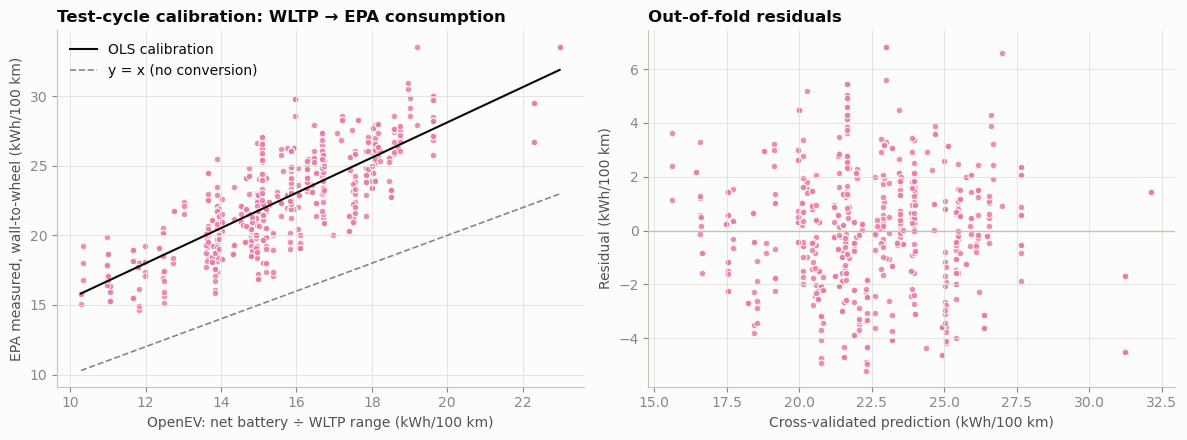

In [33]:
PT_COLORS = {"ICE": "#2a78d6", "MHEV": "#eb6834", "HEV": "#1baf7a", "PHEV": "#eda100", "BEV": "#e87ba4"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 2,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.scatter(X[:, 0], y, s=22, color=PT_COLORS["BEV"], edgecolor="#fcfcfb", linewidth=0.8, alpha=0.85)
xx = np.linspace(X.min(), X.max(), 50)
ax.plot(xx, calib.intercept_ + calib.coef_[0] * xx, color="#0b0b0b", lw=1.5, label="OLS calibration")
ax.plot(xx, xx, color="#898781", lw=1.2, ls="--", label="y = x (no conversion)")
ax.set(xlabel="OpenEV: net battery ÷ WLTP range (kWh/100 km)", ylabel="EPA measured, wall-to-wheel (kWh/100 km)",
       title="Test-cycle calibration: WLTP → EPA consumption")
ax.legend(frameon=False)
ax = axes[1]
ax.scatter(cv_pred, resid, s=22, color=PT_COLORS["BEV"], edgecolor="#fcfcfb", linewidth=0.8, alpha=0.85)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(xlabel="Cross-validated prediction (kWh/100 km)", ylabel="Residual (kWh/100 km)", title="Out-of-fold residuals")
plt.tight_layout(); plt.show()

**Interpretation**
* The out-of-fold error is about **1.7 kWh/100 km (≈ 8 %)**, roughly **4× better** than naively using the WLTP figure (MAE 7.0). The R² (~0.6) is moderate. EV consumption spans a narrow range, and part of the remaining noise is the OpenEV range errors noted earlier.
* The coefficients:
  * slope ≈ 1.27: the harsher EPA cycle scales consumption up proportionally;
  * intercept ≈ +2.8 kWh: the fixed charging losses and auxiliaries that WLTP battery-to-wheel figures exclude.
* The residuals show no strong curvature, so a linear form is adequate.

In [34]:
specs = {"WLTP only": [], "+ vehicle class": ["vehicle_class"], "+ class + drivetrain": ["vehicle_class", "drivetrain"],
         "+ class + drivetrain + power": ["vehicle_class", "drivetrain", "power_kw"]}
rows = []
for name, extra in specs.items():
    Xs = pd.get_dummies(cal[["kwh_100km_wltp_btw"] + extra], drop_first=True).astype(float)
    ok = Xs.notna().all(axis=1)
    p = cross_val_predict(LinearRegression(), Xs[ok], y[ok], groups=groups[ok], cv=GroupKFold(n_splits=5))
    e = y[ok] - p
    rows.append({"specification": name, "n": int(ok.sum()), "cv_R2": 1 - (e ** 2).sum() / ((y[ok] - y[ok].mean()) ** 2).sum(),
                 "cv_MAE": np.abs(e).mean()})
pd.DataFrame(rows).round(3)

,specification,n,cv_R2,cv_MAE
0,WLTP only,607,0.60,1.73
1,+ vehicle class,607,0.61,1.71
2,+ class + drivetrain,607,0.66,1.62
3,+ class + drivetrain + power,607,0.65,1.61


In [37]:
matched_models = set(zip(ev.loc[matches["oe_index"], "make_key"], ev.loc[matches["oe_index"], "model_key"]))
oe_only = ev[[(mk, md) not in matched_models for mk, md in zip(ev["make_key"], ev["model_key"])]].copy()
oe_only = oe_only[oe_only["year"].between(YEAR_MIN, YEAR_MAX)]
print(f"OpenEV trims whose model never appears in fueleconomy.gov: {len(oe_only)} "
      f"({oe_only[['make_key', 'model_key']].drop_duplicates().shape[0]} models, {oe_only['make_name'].nunique()} makes)")

est = calib.intercept_ + calib.coef_[0] * oe_only["kwh_100km_wltp_btw"]
# fallback for trims without WLTP: convert measured EPA battery-to-wheel using the WLTP->EPA range ratio
est = est.fillna(calib.intercept_ + calib.coef_[0] * oe_only["kwh_100km_epa_btw"] * EPA_PER_WLTP)

appended = pd.DataFrame({
    "vehicle_id": "OE-" + oe_only["unique_code"],
    "source": "OpenEV",
    "year": oe_only["year"], "make": oe_only["make_name"], "model": oe_only["model_name"],
    "trim": (oe_only["trim_name"] + " " + oe_only["variant_name"].fillna("")).str.strip(),
    "powertrain": "BEV", "fuel_grade": "Electricity", "fuel_family": "Electricity",
    "vehicle_class": oe_only["vehicle_class"], "size_class": oe_only["vehicle_class"],
    "drivetrain": oe_only["drivetrain"], "transmission_type": "Single-speed", "n_gears": 1.0,
    "elec_kwh_100km_comb": est, "energy_kwh_100km": est, "consumption_estimated": True,
    "co2_g_km": 0.0, "range_km": oe_only["range_epa_equiv_km"],
    "range_epa_is_estimated": oe_only["range_epa_is_estimated"],
    "power_kw": oe_only["system_power_kw"].astype(float),
    **{new: oe_only[old] for old, new in OE_KEEP.items() if new != "oe_system_power_kw"},
})
no_range = appended["elec_kwh_100km_comb"].isna()
print(f"excluded {no_range.sum()} trims with neither WLTP nor EPA range (consumption cannot be derived); top makes:",
      appended.loc[no_range, "make"].value_counts().head(6).to_dict())
appended = appended[~no_range]
appended = appended[appended["elec_kwh_100km_comb"].between(8, 70)]
print(f"appended rows after requiring a usable consumption estimate: {len(appended)}")
appended["make"].value_counts().head(15).to_frame("trims").T

OpenEV trims whose model never appears in fueleconomy.gov: 701 (186 models, 55 makes)
excluded 324 trims with neither WLTP nor EPA range (consumption cannot be derived); top makes: {'NIO': 65, 'XPeng': 31, 'Leapmotor': 20, 'Chery': 19, 'GAC Aion': 19, 'Geely': 19}
appended rows after requiring a usable consumption estimate: 377


make,BYD,Zeekr,Land Rover,Škoda,Renault,Peugeot,Citroën,Volkswagen,MG,Mercedes-Benz,Voyah,Fiat,Cupra,GAC Aion,Lotus
trims,34,32,24,23,21,19,18,18,17,15,12,12,12,12,11


## Running-cost and charging-infrastructure features

In [46]:
df = pd.concat([fe.assign(vehicle_id="FE-" + fe["id"].astype(str), trim=np.nan, consumption_estimated=False,
                          range_epa_is_estimated=False),
                appended], ignore_index=True, sort=False)
log_step("append OpenEV-only BEV trims", df)

elec_price = HOME_CHARGING_SHARE * PRICE_MYR["elec_home"] + (1 - HOME_CHARGING_SHARE) * PRICE_MYR["elec_dc"]
fuel_price = df["fuel_grade"].map({"Regular": PRICE_MYR["RON95"], "Premium": PRICE_MYR["RON97"],
                                   "Diesel": PRICE_MYR["Diesel"]})
fuel_cost = df["fuel_l_100km_comb"] * fuel_price
elec_cost = df["elec_kwh_100km_comb"] * elec_price
uf = df["phev_utility_factor"]
df["cost_myr_100km"] = np.select(
    [df["powertrain"].eq("BEV"), df["powertrain"].eq("PHEV")],
    [elec_cost, uf * elec_cost + (1 - uf) * fuel_cost], default=fuel_cost)
df["annual_cost_myr"] = df["cost_myr_100km"] * ANNUAL_KM / 100
df["annual_fuel_cost_usd"] = df["fuelCost08"]

is_ev = df["powertrain"].eq("BEV")
df["usable_range_km"] = np.where(is_ev, 0.7 * df["range_km"], np.nan)
df["dc_10_80_min_est"] = 0.7 * df["battery_net_kwh"] / (0.7 * df["dc_max_kw"]) * 60
df["km_per_charge_min"] = df["usable_range_km"] / df["dc_10_80_min_est"]
print(f"blended electricity price = RM {elec_price:.3f}/kWh")
df.groupby("powertrain")[["cost_myr_100km", "annual_cost_myr", "annual_fuel_cost_usd"]].median()

append OpenEV-only BEV trims                            rows = 15,654
blended electricity price = RM 0.705/kWh


,cost_myr_100km,annual_cost_myr,annual_fuel_cost_usd
powertrain,,,
BEV,15.77,"3,154.08",800.00
HEV,12.65,"2,530.15","1,800.00"
ICE,38.42,"7,683.68","3,400.00"
MHEV,48.02,"9,604.60","3,550.00"
PHEV,32.07,"6,414.75","3,050.00"


### Final Variables, Missing Values, Outliers

In [38]:
RENAME = {"displ": "engine_displacement_l", "cylinders": "engine_cylinders", "feScore": "epa_fe_score",
          "ghgScore": "epa_ghg_score", "baseModel": "base_model", "VClass": "epa_vehicle_class"}
df = df.rename(columns=RENAME)
FINAL_COLS = [
    # identity & provenance
    "vehicle_id", "source", "year", "make", "model", "base_model", "trim", "oe_unique_code",
    "match_confidence", "match_year_gap", "consumption_estimated", "range_epa_is_estimated",
    # classification
    "powertrain", "fuel_grade", "fuel_family", "flex_fuel", "vehicle_class", "size_class", "epa_vehicle_class",
    "drivetrain", "transmission_type", "n_gears",
    # engine / motor
    "engine_displacement_l", "engine_cylinders", "turbo", "supercharger", "start_stop", "battery_voltage",
    "power_kw", "torque_nm", "accel_0_100_s", "top_speed_kmh",
    # consumption & emissions (metric)
    "fuel_l_100km_city", "fuel_l_100km_hwy", "fuel_l_100km_comb",
    "elec_kwh_100km_city", "elec_kwh_100km_hwy", "elec_kwh_100km_comb",
    "energy_kwh_100km", "mpg_or_mpge_comb", "co2_g_km", "epa_fe_score", "epa_ghg_score", "gas_guzzler",
    # electric range & battery
    "range_km", "range_wltp_km", "usable_range_km", "phev_elec_range_km", "phev_utility_factor", "phev_blended",
    "battery_net_kwh", "battery_gross_kwh", "battery_chemistry",
    # charging infrastructure
    "has_dc_charging", "dc_max_kw", "ac_max_kw", "dc_c_rate", "charge_connectors", "primary_connector",
    "charge_time_240v_h", "dc_10_80_min_est", "km_per_charge_min",
    # running cost
    "cost_myr_100km", "annual_cost_myr", "annual_fuel_cost_usd",
]
df = df[FINAL_COLS].copy()
print(df.shape)

(15654, 65)


### MISSING VALUES

In [39]:
key_cols = ["engine_displacement_l", "power_kw", "fuel_l_100km_comb", "elec_kwh_100km_comb", "energy_kwh_100km",
            "co2_g_km", "range_km", "battery_net_kwh", "dc_max_kw", "primary_connector", "cost_myr_100km",
            "annual_fuel_cost_usd", "epa_fe_score"]
miss = (df.groupby("powertrain")[key_cols].apply(lambda g: g.isna().mean() * 100).round(0)
        .reindex(["ICE", "MHEV", "HEV", "PHEV", "BEV"]))
miss.style.background_gradient(cmap="Blues", vmin=0, vmax=100).format("{:.0f}%")

,engine_displacement_l,power_kw,fuel_l_100km_comb,elec_kwh_100km_comb,energy_kwh_100km,co2_g_km,range_km,battery_net_kwh,dc_max_kw,primary_connector,cost_myr_100km,annual_fuel_cost_usd,epa_fe_score
powertrain,,,,,,,,,,,,,
ICE,0%,100%,0%,100%,0%,0%,100%,100%,100%,100%,0%,0%,0%
MHEV,0%,100%,0%,100%,0%,0%,100%,100%,100%,100%,0%,0%,0%
HEV,0%,100%,0%,100%,0%,0%,100%,100%,100%,100%,0%,0%,0%
PHEV,0%,0%,0%,0%,0%,0%,100%,100%,100%,100%,0%,0%,0%
BEV,100%,1%,100%,0%,0%,0%,0%,26%,29%,22%,0%,22%,22%


### OUTLIERS (FLAGGING ONLY)

In [40]:
def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else s * 0

df["energy_robust_z"] = df.groupby("powertrain")["energy_kwh_100km"].transform(robust_z)
df["is_energy_outlier"] = df["energy_robust_z"].abs() > 3.5
print(df.groupby("powertrain")["is_energy_outlier"].agg(n_flagged="sum", share="mean").round(3).to_string())
df.loc[df["is_energy_outlier"]].sort_values("energy_robust_z", ascending=False)[
    ["year", "make", "model", "powertrain", "energy_kwh_100km", "energy_robust_z"]].head(8)

            n_flagged  share
powertrain                  
BEV                45   0.03
HEV                 8   0.01
ICE                80   0.01
MHEV                0   0.00
PHEV                0   0.00


,year,make,model,powertrain,energy_kwh_100km,energy_robust_z
9265,2019,Koenigsegg,Regera,HEV,190.39,7.95
9266,2020,Koenigsegg,Regera,HEV,190.39,7.95
13425,2024,Lamborghini,Revuelto,HEV,174.53,7.01
13552,2025,Lamborghini,Revuelto,HEV,174.53,7.01
3190,2017,Ferrari,LaFerrari Aperta,HEV,161.10,6.23
13549,2025,Bugatti,Mistral,ICE,232.70,6.17
12019,2024,Bugatti,Chiron Super Sport,ICE,232.70,6.17
10915,2023,Bugatti,Chiron Pur Sport,ICE,232.70,6.17


In [41]:
cat_cols = ["source", "make", "powertrain", "fuel_grade", "fuel_family", "vehicle_class", "size_class",
            "drivetrain", "transmission_type", "battery_chemistry", "primary_connector", "match_confidence"]
for c in cat_cols:
    df[c] = df[c].astype("category")
df["powertrain"] = df["powertrain"].cat.reorder_categories(["ICE", "MHEV", "HEV", "PHEV", "BEV"], ordered=True)
for c in ["flex_fuel", "turbo", "supercharger", "start_stop", "gas_guzzler", "phev_blended", "has_dc_charging",
          "consumption_estimated", "range_epa_is_estimated", "is_energy_outlier"]:
    df[c] = df[c].astype("boolean")
df["year"] = df["year"].astype(int)
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.dtypes.astype(str).value_counts()

memory: 10.7 MB


float64     37
category    12
boolean     10
object       7
int64        1
Name: count, dtype: int64

# VALIDATION

In [42]:
assert df["vehicle_id"].is_unique, "duplicate vehicle_id"
assert df["year"].between(YEAR_MIN, YEAR_MAX).all()
assert df["powertrain"].notna().all() and df["energy_kwh_100km"].notna().all()
assert df["cost_myr_100km"].notna().all() and (df["cost_myr_100km"] > 0).all()
assert (df.loc[df.powertrain.eq("BEV"), "co2_g_km"] == 0).all()
assert df.loc[df.powertrain.isin(["ICE", "MHEV", "HEV"]), "fuel_l_100km_comb"].notna().all()
assert df.loc[df.powertrain.eq("BEV"), ["elec_kwh_100km_comb", "range_km"]].notna().all().all()
bat = df[["battery_gross_kwh", "battery_net_kwh"]].dropna()
assert (bat["battery_gross_kwh"] >= bat["battery_net_kwh"]).all(), "gross battery smaller than net"
print("all validation checks passed")

all validation checks passed


### SAVE OUTPUTS (CSV AND PARQUET because why not)

In [ ]:
DESCRIPTIONS = {
    "vehicle_id": "Unique id: FE-<fueleconomy.gov id> or OE-<OpenEV unique_code>",
    "year": "Model year", "make": "Manufacturer", "model": "Model name (FE: includes trim/wheel info)",
    "base_model": "EPA base model name",
    "source": "Provenance: fueleconomy.gov only, fueleconomy.gov + OpenEV enrichment, or OpenEV only",
    "trim": "Trim/variant (OpenEV-only rows; FE encodes trim inside `model`)",
    "oe_unique_code": "Matched OpenEV record", "match_confidence": "Entity-resolution confidence (range agreement)",
    "match_year_gap": "|FE year - OpenEV year| of the match",
    "consumption_estimated": "True if elec consumption was estimated via WLTP->EPA calibration",
    "range_epa_is_estimated": "True if range_km was converted from WLTP",
    "powertrain": "ICE, MHEV (mild hybrid), HEV (full hybrid), PHEV (plug-in), BEV (battery electric)",
    "fuel_grade": "Regular / Premium / Diesel / Electricity", "fuel_family": "Gasoline / Diesel / Electricity",
    "flex_fuel": "E85-capable", "vehicle_class": "Car, SUV, Pickup, Van, Special Purpose",
    "size_class": "Cleaned EPA size class", "epa_vehicle_class": "Original EPA VClass",
    "drivetrain": "FWD / RWD / AWD / 4WD / 2WD", "transmission_type": "Automatic, Manual, DCT, CVT, Single-speed",
    "n_gears": "Number of gears", "engine_displacement_l": "Engine displacement (L)",
    "engine_cylinders": "Number of cylinders", "turbo": "Turbocharged", "supercharger": "Supercharged",
    "start_stop": "Engine start-stop", "battery_voltage": "Hybrid battery voltage (V)",
    "power_kw": "System power (kW) from OpenEV; else sum of motor ratings parsed from FE evMotor (upper bound)", "torque_nm": "System torque (Nm)",
    "accel_0_100_s": "0-100 km/h (s)", "top_speed_kmh": "Top speed (km/h)",
    "fuel_l_100km_city": "Fuel use, city (L/100km)", "fuel_l_100km_hwy": "Fuel use, highway (L/100km)",
    "fuel_l_100km_comb": "Fuel use, combined (L/100km); PHEV = charge-sustaining",
    "elec_kwh_100km_city": "Electricity use, city (kWh/100km, wall-to-wheel)",
    "elec_kwh_100km_hwy": "Electricity use, highway (kWh/100km)",
    "elec_kwh_100km_comb": "Electricity use, combined (kWh/100km); PHEV = charge-depleting",
    "energy_kwh_100km": "Unified energy intensity, all powertrains (kWh/100km)",
    "mpg_or_mpge_comb": "Original EPA combined MPG (MPGe for BEV)", "co2_g_km": "Tailpipe CO2 (g/km)",
    "epa_fe_score": "EPA fuel-economy score 1-10", "epa_ghg_score": "EPA greenhouse-gas score 1-10",
    "gas_guzzler": "Subject to US gas-guzzler tax", "range_km": "BEV range, EPA or EPA-equivalent (km)",
    "range_wltp_km": "BEV range, WLTP (km)", "usable_range_km": "10-80% SoC range (km)",
    "phev_elec_range_km": "PHEV electric range (km)", "phev_utility_factor": "Share of km driven on electricity (EPA UF)",
    "phev_blended": "PHEV uses engine during charge-depleting mode", "battery_net_kwh": "Usable battery (kWh)",
    "battery_gross_kwh": "Gross battery (kWh)", "battery_chemistry": "li-ion / lfp / nmc",
    "has_dc_charging": "Supports DC fast charging", "dc_max_kw": "Peak DC charging power (kW)",
    "ac_max_kw": "Max AC charging power (kW)", "dc_c_rate": "Peak DC kW / net kWh",
    "charge_connectors": "All charging connectors", "primary_connector": "Primary connector (CCS2, NACS, GB/T, ...)",
    "charge_time_240v_h": "Hours to charge at 240 V (EPA)", "dc_10_80_min_est": "Estimated 10-80% DC charge time (min)",
    "km_per_charge_min": "Usable km gained per minute of DC charging",
    "cost_myr_100km": "Energy cost per 100 km (MYR, Malaysian price assumptions)",
    "annual_cost_myr": f"Annual energy cost at {ANNUAL_KM:,} km (MYR)",
    "annual_fuel_cost_usd": "EPA annual fuel cost, US prices, 15k mi (USD)",
    "energy_robust_z": "Robust z-score of energy_kwh_100km within powertrain",
    "is_energy_outlier": "|robust z| > 3.5 within powertrain",
}
dictionary = pd.DataFrame({
    "column": df.columns, "dtype": df.dtypes.astype(str).values,
    "description": [DESCRIPTIONS.get(c, "") for c in df.columns],
    "pct_missing": (df.isna().mean() * 100).round(1).values,
})
missing_desc = dictionary.loc[dictionary["description"].eq(""), "column"].tolist()
assert not missing_desc, f"undocumented columns: {missing_desc}"

df.to_parquet(OUT_DIR / "vehicles_clean.parquet", index=False)
df.to_csv(OUT_DIR / "vehicles_clean.csv", index=False)
dictionary.to_csv(OUT_DIR / "data_dictionary.csv", index=False)
with open(OUT_DIR / "assumptions.json", "w") as f:                 # shared with Notebook 2
    json.dump({"PRICE_MYR": PRICE_MYR, "HOME_CHARGING_SHARE": HOME_CHARGING_SHARE, "ANNUAL_KM": ANNUAL_KM,
               "EPA_PER_WLTP": EPA_PER_WLTP, "YEAR_MIN": YEAR_MIN, "YEAR_MAX": YEAR_MAX}, f, indent=2)
print("saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

In [43]:
lineage = pd.DataFrame(log, columns=["step", "rows"])
lineage

,step,rows
0,raw fueleconomy.gov,50407
1,model years 2015-2026,15455
2,drop hydrogen / natural-gas / LPG,15409
3,drop specification duplicates,15277
4,drop physically implausible records,15277
5,raw OpenEV,1189
6,left-join OpenEV attributes (row count unchanged),15277
7,append OpenEV-only BEV trims,15654


In [44]:
summary = (df.groupby("powertrain", observed=True)
           .agg(records=("vehicle_id", "size"), makes=("make", "nunique"),
                years=("year", lambda s: f"{s.min()}-{s.max()}"),
                with_battery_data=("battery_net_kwh", lambda s: s.notna().sum())))
summary.loc["Total"] = [len(df), df["make"].nunique(), f"{df.year.min()}-{df.year.max()}", df["battery_net_kwh"].notna().sum()]
summary

,records,makes,years,with_battery_data
powertrain,,,,
ICE,12042,52,2015-2026,0
MHEV,785,17,2015-2026,0
HEV,653,22,2015-2026,0
PHEV,424,30,2015-2026,0
BEV,1750,61,2015-2026,1287
Total,15654,82,2015-2026,1287


## Summary
1. **Scoped** fueleconomy.gov to model years 2015–2026. Removed out-of-scope fuels (hydrogen, CNG, LPG).
2. **Recovered hidden missing values**: `-1` and `0` sentinels became `NaN`, and true zeros (EV tailpipe CO₂) were set explicitly.
3. **Standardised** makes, drivetrains (7 labels → 5), vehicle classes (34 → 13 size classes / 5 coarse classes) and transmissions (34 codes → 5 types + gear count).
4. **Built a powertrain taxonomy**: ICE / MHEV / HEV / PHEV / BEV. Mild hybrids were separated from full hybrids, and the split was validated by their city fuel economy.
5. **Converted everything to metric** and to a **unified energy scale** (kWh/100 km) so ICE, HEV and EV can be compared directly.
6. **Removed specification duplicates** and **physically implausible** records.
7. **Resolved entities across sources** with a strict, two-stage matcher, then validated it statistically (EPA-range agreement: CCC, Bland–Altman).
8. **Left-joined** OpenEV battery and charging attributes. Trim-specific fields from low-confidence matches were nulled out.
9. **Appended OpenEV-only EVs** after **calibrating WLTP to EPA** consumption (cross-validated by car model), with every estimate flagged.
10. **Engineered targets and infrastructure features**: MYR cost per 100 km, annual cost, usable range, estimated DC charging time, and km gained per charging minute.
11. **Flagged (not deleted) outliers** using the robust z-score within each powertrain. **Validated** invariants with assertions, then **saved** the data with a data dictionary and full lineage.
